In [69]:
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import subprocess as sbp
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import delayed, Parallel

In [70]:
# load our popes
d = pd.read_csv("../popes-list.csv")

# for making our example power calculation we will use
# two specific intervals of 200 and 500 years as examples

start_idx = d.query("start > 1045").index.min()
end_200_idx = d.query("start >= 1245").index.min()
end_500_idx = d.query("start >= 1545").index.min()

d_start = d.iloc[:start_idx]
ic = " ".join([str(x) for x in d_start["name"].value_counts()])

d_end = d.iloc[:end_200_idx]
n_200 = d_end.shape[0]
k_200 = len(d_end["name"].unique())

d_end = d.iloc[:end_500_idx]
n_500 = d_end.shape[0]
k_500 = len(d_end["name"].unique())

In [56]:
# for both these intervals, we want to run Slatkin's and Watterson's tests
#  (testing for neutral model)
# while varying the data-generating model
#  (our frequency-dependent model)


def sample_configurations(n, k, initial_configuration, bias=1.0, samples=100, seed=231):
    if bias != 1.0:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' --bias {bias} -c tabular {int(samples)}"
    else:
        cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} --initial-configuration '{initial_configuration}' -c tabular {int(samples)}"

    s = sbp.getoutput(cmd).split("\n")
    return s


# this does the `kind` test for the `configuration` conditional on `initial_configuration`
# assuming the model having `bias` as the null
def run_test_conditional(
    n,
    k,
    configuration,
    initial_configuration,
    bias=1.0,
    samples=1e8,
    seed=234,
    kind="slatkin",
):
    if kind != "slatkin" and kind != "watterson":
        raise ValueError(f"invalid test kind: {kind}")
    if bias == 1.0:
        bstr = ""
    else:
        bstr = f"-b {bias} "
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {bstr}--initial-configuration '{initial_configuration}' {int(samples)} | ewens-sampler test {kind} '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


# here `b_gen` is the alternative model for generating data to be tested
#  and `b_test` is the null model for running the test
def run_grid(n, k, ic, b_gen, b_test, kind="slatkin", samples=10000):
    rng = np.random.default_rng(int(n + k + 100 * b_gen + 100 * b_test))

    rows = []
    for tc in sample_configurations(
        n, k, ic, bias=b_gen, samples=100, seed=rng.choice(int(1e6))
    ):
        pval = run_test_conditional(
            n,
            k,
            tc,
            ic,
            bias=b_test,
            samples=samples,
            seed=rng.choice(int(1e6)),
            kind=kind,
        )

        rows.append(
            {
                "bias_gen": b_gen,
                "bias_test": b_test,
                "n": n,
                "k": k,
                "pval": pval,
                "kind": kind,
            }
        )

    return pd.DataFrame.from_records(rows)

In [18]:
# we will only test for the neutral model, like in the paper
bias_grid = [
    (x, y, kind)
    for x in [0.33, 0.5, 0.8, 0.9, 1.0, 1.11, 1.25, 2, 3]
    for y in [1.0]
    for kind in ["slatkin", "watterson"]
]

results_200 = list(
    tqdm(
        Parallel(n_jobs=-1, return_as="generator")(
            delayed(run_grid)(n_200, k_200, ic, bg, bt, kind)
            for (bg, bt, kind) in bias_grid
        ),
        total=len(bias_grid),
    )
)
results_500 = list(
    tqdm(
        Parallel(n_jobs=-1, return_as="generator")(
            delayed(run_grid)(n_500, k_500, ic, bg, bt, kind)
            for (bg, bt, kind) in bias_grid
        ),
        total=len(bias_grid),
    )
)

ans = pd.concat(results_200 + results_500)
ans.to_csv("output/statpower_interval.csv")

  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/18 [00:00<?, ?it/s]

In [71]:
def onetail(x, alpha=0.05):
    return x[x < alpha].shape[0]


def twotail(x, alpha=0.05):
    return x[(x < alpha / 2) | (x > (1 - alpha / 2))].shape[0]


power_df = (
    pd.read_csv("output/statpower_interval.csv")
    .groupby(["kind", "bias_gen", "bias_test", "n", "k"])
    .agg({"pval": ["count", onetail, twotail]})
    .reset_index()
)
power_df.columns = [
    "kind",
    "bias_gen",
    "bias_test",
    "n",
    "k",
    "total",
    "onetail",
    "twotail",
]
power_df["onetail"] = power_df["onetail"] / power_df["total"]
power_df["twotail"] = power_df["twotail"] / power_df["total"]

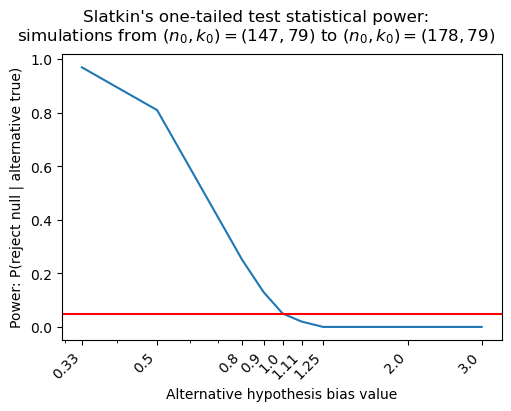

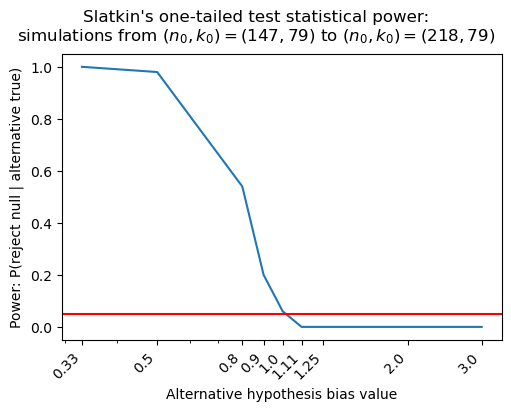

In [73]:
dplot = power_df.query("n == 178 and kind == 'slatkin'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="onetail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Slatkin's one-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (178, 79)$"
)

fig.savefig("plots/statpower_slatkin_ot_n31.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_slatkin_ot_n31.png", dpi=600, bbox_inches="tight")

dplot = power_df.query("n == 218 and kind == 'slatkin'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="onetail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Slatkin's one-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (218, 79)$"
)

fig.savefig("plots/statpower_slatkin_ot_n71.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_slatkin_ot_n71.png", dpi=600, bbox_inches="tight")

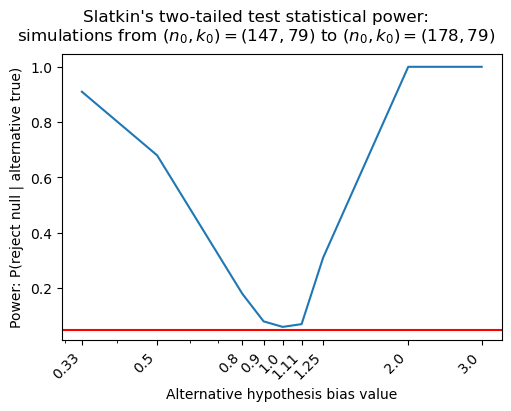

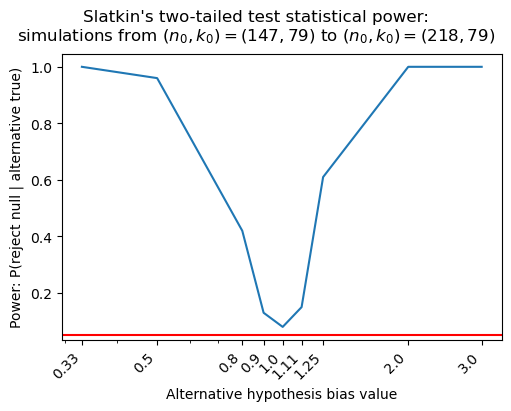

In [74]:
dplot = power_df.query("n == 178 and kind == 'slatkin'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="twotail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Slatkin's two-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (178, 79)$"
)

fig.savefig("plots/statpower_slatkin_tt_n31.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_slatkin_tt_n31.png", dpi=600, bbox_inches="tight")

dplot = power_df.query("n == 218 and kind == 'slatkin'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="twotail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Slatkin's two-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (218, 79)$"
)

fig.savefig("plots/statpower_slatkin_tt_n71.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_slatkin_tt_n71.png", dpi=600, bbox_inches="tight")

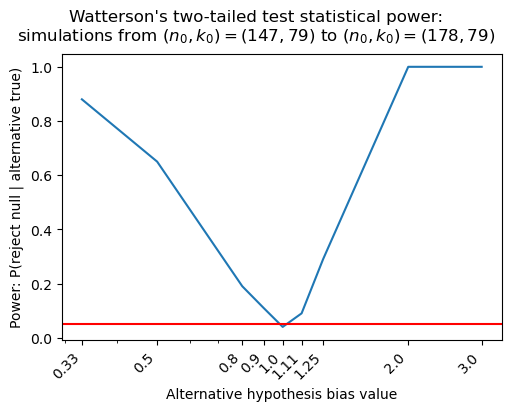

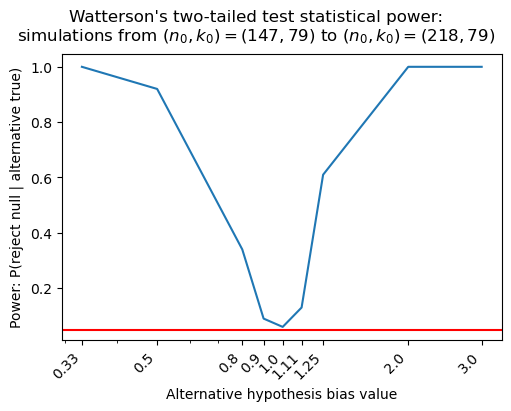

In [75]:
dplot = power_df.query("n == 178 and kind == 'watterson'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="twotail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Watterson's two-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (178, 79)$"
)

fig.savefig("plots/statpower_watterson_tt_n31.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_watterson_tt_n31.png", dpi=600, bbox_inches="tight")

dplot = power_df.query("n == 218 and kind == 'watterson'")
palette = sns.color_palette("muted", n_colors=7)
fig, ax = plt.subplots(1, figsize=(5, 4), constrained_layout=True)

sns.lineplot(dplot, x="bias_gen", y="twotail", ax=ax)
ax.axhline(y=0.05, color="red")

ax.set_xlabel("Alternative hypothesis bias value")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_xscale("log")

biases = sorted(set(power_df["bias_gen"]))
ax.set_xticks(biases)
ax.set_xticklabels(biases, rotation=45, ha="right")

fig.suptitle(
    "Watterson's two-tailed test statistical power:\nsimulations from $(n_0,k_0) = (147, 79)$ to $(n_0,k_0) = (218, 79)$"
)

fig.savefig("plots/statpower_watterson_tt_n71.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_watterson_tt_n71.png", dpi=600, bbox_inches="tight")

In [60]:
# let's also do power in windows! to mirror our figures

popes = pd.read_csv("../popes-list.csv")


def run_power_windows(popes, s, size):
    e = s + size
    d = popes.query("start <= @s")

    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]
    initial_configuration = " ".join([str(x) for x in d["name"].value_counts()])
    n0 = d.shape[0]
    k0 = len(d["name"].unique())

    d_end = popes.query("start < @e")
    end_configuration = " ".join([str(x) for x in d_end["name"].value_counts()])
    n = d_end.shape[0]
    k = len(d_end["name"].unique())

    rows = []
    for bias in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.11, 1.25, 1.43, 1.67, 2]:
        for kind in ["slatkin", "watterson"]:
            for i, tc in enumerate(
                sample_configurations(
                    n,
                    k,
                    initial_configuration,
                    bias=bias,
                    samples=100,
                    seed=int(n + k + bias * 1000 + 2),
                )
            ):
                p_tail = run_test_conditional(
                    n,
                    k,
                    tc,
                    initial_configuration,
                    samples=10000,
                    seed=int(n + k + bias * 1000),
                    kind=kind,
                )
                rows.append(
                    {
                        "year": year,
                        "pope": pope,
                        "n": n,
                        "k": k,
                        "window_start": s,
                        "window_end": e,
                        "window_size": size,
                        "n0": n0,
                        "k0": k0,
                        "bias": bias,
                        "rep": i,
                        "sim_configuration": tc,
                        "p_tail": p_tail,
                        "kind": kind,
                    }
                )
    return pd.DataFrame.from_records(rows)


inputs = []
for size in [200]:
    for s in popes.query("start >= 432 and start < 2025 - @size + 5")["start"]:
        inputs.append((popes, s, size))

results = Parallel(n_jobs=-1)(delayed(run_power_windows)(*y) for y in inputs)
power_windf = pd.concat(results)
power_windf.to_csv("output/power_windows.csv", index=False)

In [76]:
power_windf = (
    pd.read_csv("output/power_windows.csv")
    .groupby(["kind", "year", "pope", "n", "k", "window_start", "window_end", "bias"])
    .agg({"p_tail": ["count", onetail, twotail]})
    .reset_index()
)
power_windf.columns = [
    "kind",
    "year",
    "pope",
    "n",
    "k",
    "window_start",
    "window_end",
    "bias",
    "total",
    "onetail",
    "twotail",
]
power_windf["onetail"] = power_windf["onetail"] / power_windf["total"]
power_windf["twotail"] = power_windf["twotail"] / power_windf["total"]
power_windf["bias"] = power_windf["bias"].astype(str)
power_windf

,kind,year,pope,n,k,window_start,window_end,bias,total,onetail,twotail
0,slatkin,432,Sixtus III,70,58,432,632,0.5,100,0.00,0.00
1,slatkin,432,Sixtus III,70,58,432,632,0.6,100,0.00,0.00
2,slatkin,432,Sixtus III,70,58,432,632,0.7,100,0.00,0.00
3,slatkin,432,Sixtus III,70,58,432,632,0.8,100,0.00,0.00
4,slatkin,432,Sixtus III,70,58,432,632,0.9,100,0.00,0.01
...,...,...,...,...,...,...,...,...,...,...,...
4241,watterson,1829,Pius VIII,265,81,1829,2029,1.11,100,0.01,0.07
4242,watterson,1829,Pius VIII,265,81,1829,2029,1.25,100,0.00,0.16
4243,watterson,1829,Pius VIII,265,81,1829,2029,1.43,100,0.00,0.28
4244,watterson,1829,Pius VIII,265,81,1829,2029,1.67,100,0.00,0.51


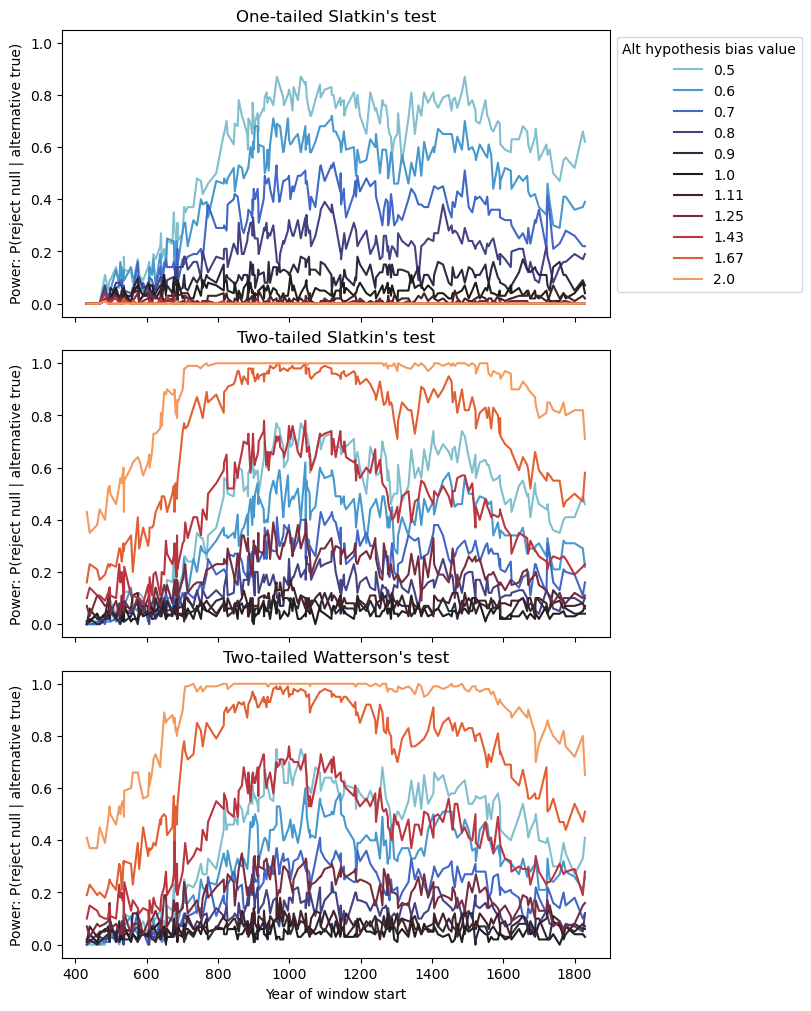

In [77]:
palette = sns.color_palette("muted", n_colors=7)
fig, axs = plt.subplots(
    3, 1, figsize=(8, 10), constrained_layout=True, sharex=True, sharey=True
)

dplot = power_windf.query("kind == 'slatkin'")

ax = axs[0]
sns.lineplot(
    dplot,
    x="window_start",
    y="onetail",
    hue="bias",
    ax=ax,
    palette=sns.color_palette("icefire", 11),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
:1ax.set_title("One-tailed Slatkin's test")

ax = axs[1]
sns.lineplot(
    dplot,
    x="year",
    y="twotail",
    hue="bias",
    ax=ax,
    legend=False,
    palette=sns.color_palette("icefire", 11),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_title("Two-tailed Slatkin's test")

dplot = power_windf.query("kind == 'watterson'")

ax = axs[2]
sns.lineplot(
    dplot,
    x="year",
    y="twotail",
    hue="bias",
    ax=ax,
    legend=False,
    palette=sns.color_palette("icefire", 11),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_title("Two-tailed Watterson's test")

fig.suptitle("Statistical power of windowed (conditional) tests")

fig.savefig("plots/statpower_windows_200.pdf", bbox_inches="tight")
fig.savefig("plots/statpower_windows_200.png", dpi=600, bbox_inches="tight")

In [81]:
popes = pd.read_csv("../popes-list.csv")


def run_test(n, k, configuration, bias=1.0, samples=1e8, seed=234, kind="slatkin"):
    if kind != "slatkin" and kind != "watterson":
        raise ValueError(f"invalid test kind: {kind}")
    if bias == 1.0:
        bstr = ""
    else:
        bstr = f"-b {bias} "
    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {bstr}{int(samples)} | ewens-sampler test {kind} '{configuration}'"

    result = sbp.getoutput(cmd).split()
    count, total = int(result[0]), int(result[1])

    return count / total


def sample_configurations_full(n, k, bias=1.0, samples=100, seed=231):
    if bias == 1.0:
        bstr = ""
    else:
        bstr = f"-b {bias} "

    cmd = f"ewens-sampler sample --seed {seed} -n {n} -k {k} {bstr}-c tabular {int(samples)}"

    s = sbp.getoutput(cmd).split("\n")
    return s


def run_power(d, kind):
    year = d["start"].iloc[-1]
    pope = d["pope"].iloc[-1]

    n, k = d.shape[0], len(d["name"].unique())
    rows = []
    for bias in [0.5, 0.6, 0.7, 0.8, 1.0, 1.25, 1.43, 1.67, 2]:
        for i, tc in enumerate(
            sample_configurations_full(
                n, k, bias=bias, samples=100, seed=int(n + k + bias * 1000 + 2)
            )
        ):
            p_tail = run_test(
                n, k, tc, samples=10000, seed=int(n + k + bias * 1000), kind=kind
            )
            rows.append(
                {
                    "year": year,
                    "pope": pope,
                    "n": n,
                    "k": k,
                    "bias": bias,
                    "rep": i,
                    "sim_configuration": tc,
                    "p_tail": p_tail,
                    "kind": kind,
                }
            )
    return pd.DataFrame.from_records(rows)


args = [
    (popes.iloc[:i, :], kind)
    for i in range(44, popes.shape[0] + 1)
    for kind in ["watterson", "slatkin"]
]

results = list(
    tqdm(
        Parallel(n_jobs=-1, return_as="generator")(
            delayed(run_power)(*y) for y in args
        ),
        total=len(args),
    )
)
power_df = pd.concat(results)
power_df.to_csv("output/power.csv", index=False)

/nix/store/2i22v5s4bvyvaavcf4d00463kpihhvjn-python3-3.13.13-env/lib/python3.13/site-packages/joblib/parallel.py:1886: UserWarning: 48 tasks which were still being processed by the workers have been cancelled. You could benefit from adjusting the input task iterator to limit unnecessary computation time.
  warnings.warn(msg)


  0%|          | 0/444 [00:00<?, ?it/s]

In [84]:
power_df = (
    pd.read_csv("output/power.csv")
    .groupby(["kind", "year", "pope", "n", "k", "bias"])
    .agg({"p_tail": ["count", onetail, twotail]})
    .reset_index()
)
power_df.columns = [
    "kind",
    "year",
    "pope",
    "n",
    "k",
    "bias",
    "total",
    "onetail",
    "twotail",
]
power_df["onetail"] = power_df["onetail"] / power_df["total"]
power_df["twotail"] = power_df["twotail"] / power_df["total"]
power_df["bias"] = power_df["bias"].astype(str)

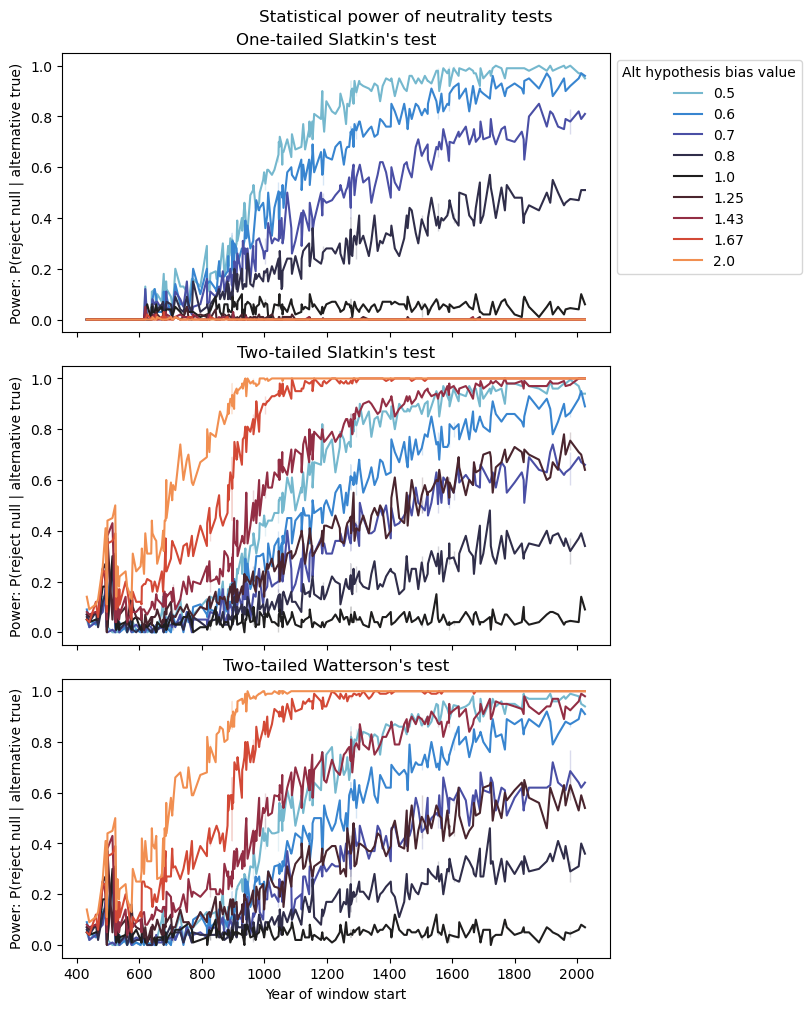

In [87]:
palette = sns.color_palette("muted", n_colors=7)
fig, axs = plt.subplots(
    3, 1, figsize=(8, 10), constrained_layout=True, sharex=True, sharey=True
)

biases = set(power_df["bias"])
dplot = power_df.query("kind == 'slatkin'")

ax = axs[0]
sns.lineplot(
    dplot,
    x="year",
    y="onetail",
    hue="bias",
    ax=ax,
    palette=sns.color_palette("icefire", len(biases)),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.legend(title=("Alt hypothesis bias value"), loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("One-tailed Slatkin's test")

ax = axs[1]
sns.lineplot(
    dplot,
    x="year",
    y="twotail",
    hue="bias",
    ax=ax,
    legend=False,
    palette=sns.color_palette("icefire", len(biases)),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_title("Two-tailed Slatkin's test")

dplot = power_df.query("kind == 'watterson'")

ax = axs[2]
sns.lineplot(
    dplot,
    x="year",
    y="twotail",
    hue="bias",
    ax=ax,
    legend=False,
    palette=sns.color_palette("icefire", len(biases)),
)

ax.set_xlabel("Year of window start")
ax.set_ylabel("Power: P(reject null | alternative true)")
ax.set_title("Two-tailed Watterson's test")

fig.suptitle("Statistical power of neutrality tests")

fig.savefig("plots/statpower.pdf", bbox_inches="tight")
fig.savefig("plots/statpower.png", dpi=600, bbox_inches="tight")